In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

SEED = 17
FIELDS = ['variance', 'skewness', 'curtosis', 'entropy', 'class']
DATA_URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt'
notes = pd.read_csv(DATA_URL, header=None, names=FIELDS)
print('Shape:', notes.shape, '| Missing:', notes.isna().sum().sum(), '| Duplicates:', notes.duplicated().sum())
print(notes['class'].value_counts().sort_index())
display(notes.head())

Shape: (1372, 5) | Missing: 0 | Duplicates: 24
class
0    762
1    610
Name: count, dtype: int64


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


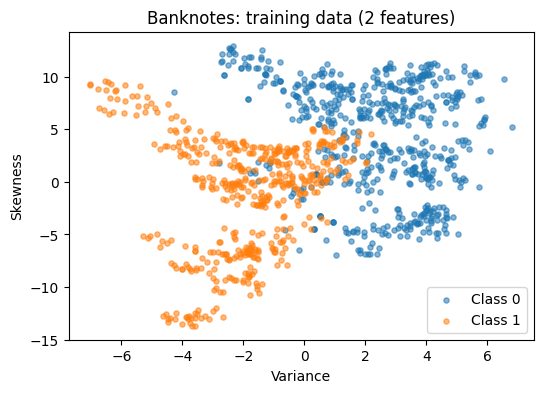

In [3]:
inputs = notes[FIELDS[:-1]].to_numpy(dtype=float)
targets = notes['class'].to_numpy(dtype=int)
row_train, row_test = train_test_split(np.arange(len(targets)), test_size=0.2,
                                       stratify=targets, random_state=SEED)
train_all, test_all = inputs[row_train], inputs[row_test]
train_2, test_2 = train_all[:, :2], test_all[:, :2]
y_train, y_test = targets[row_train], targets[row_test]

fig, ax = plt.subplots(figsize=(6, 4))
for label in (0, 1):
    group = y_train == label
    ax.scatter(train_2[group, 0], train_2[group, 1], s=14, alpha=.55, label=f'Class {label}')
ax.set(xlabel='Variance', ylabel='Skewness', title='Banknotes: training data (2 features)')
ax.legend(); plt.show()

## PART A

In [4]:
def node_impurity(labels, kind='gini'):
    counts = np.bincount(labels.astype(int), minlength=2)
    probs = counts[counts > 0] / counts.sum()
    return float(1 - np.dot(probs, probs)) if kind == 'gini' else float(-(probs * np.log2(probs)).sum())


def optimal_cut(matrix, labels, kind):
    
    size, dims = matrix.shape
    best = (float('inf'), None, None)
    for column in range(dims):
        ordering = np.argsort(matrix[:, column], kind='mergesort')
        sorted_x, sorted_y = matrix[ordering, column], labels[ordering]
        valid = np.flatnonzero(sorted_x[:-1] < sorted_x[1:])
        if not valid.size:
            continue
        left_n = valid + 1
        right_n = size - left_n
        positives_left = np.cumsum(sorted_y)[valid]
        positives_right = sorted_y.sum() - positives_left
        if kind == 'gini':
            left_p = positives_left / left_n
            right_p = positives_right / right_n
            left_score = 2 * left_p * (1 - left_p)
            right_score = 2 * right_p * (1 - right_p)
        else:
            def binary_entropy(p):
                return -(np.where(p > 0, p * np.log2(np.clip(p, 1e-12, 1)), 0) +
                         np.where(p < 1, (1-p) * np.log2(np.clip(1-p, 1e-12, 1)), 0))
            left_score = binary_entropy(positives_left / left_n)
            right_score = binary_entropy(positives_right / right_n)
        scores = (left_n * left_score + right_n * right_score) / size
        choice = np.argmin(scores)
        if scores[choice] < best[0] - 1e-12:
            position = valid[choice]
            best = (float(scores[choice]), column,
                    float((sorted_x[position] + sorted_x[position+1]) / 2))
    return best


class ScratchTree:
    def __init__(self, depth_limit=4, criterion='gini', min_leaf=1):
        self.depth_limit, self.criterion, self.min_leaf = depth_limit, criterion, min_leaf

    def fit(self, matrix, labels):
        self.root_ = self._grow(np.asarray(matrix), np.asarray(labels, dtype=int), 0)
        return self

    def _grow(self, matrix, labels, level):
        counts = np.bincount(labels, minlength=2)
        root = {'label': int(np.argmax(counts)), 'counts': counts, 'n': len(labels)}
        if (level >= self.depth_limit or np.count_nonzero(counts) == 1 or
                len(labels) < 2 * self.min_leaf):
            return root
        _, feature, cut = optimal_cut(matrix, labels, self.criterion)
        if feature is None:
            return root
        goes_left = matrix[:, feature] <= cut
        if min(goes_left.sum(), (~goes_left).sum()) < self.min_leaf:
            return root
        root.update(feature=feature, threshold=cut,
                    left=self._grow(matrix[goes_left], labels[goes_left], level+1),
                    right=self._grow(matrix[~goes_left], labels[~goes_left], level+1))
        return root

    def predict(self, matrix):
        outcomes = []
        for example in np.asarray(matrix):
            branch = self.root_
            while 'feature' in branch:
                branch = branch['left'] if example[branch['feature']] <= branch['threshold'] else branch['right']
            outcomes.append(branch['label'])
        return np.asarray(outcomes)

In [5]:
toy_x = np.array([[0], [1], [2], [3], [4]], dtype=float)
toy_y = np.array([0, 0, 0, 1, 1])
assert np.array_equal(ScratchTree(depth_limit=2).fit(toy_x, toy_y).predict(toy_x), toy_y)
print('Toy data: tree splits correctly.')

own_tree_2 = ScratchTree(depth_limit=4).fit(train_2, y_train)
sk_tree_2 = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=SEED).fit(train_2, y_train)
print('Manual 2D accuracy:', accuracy_score(y_test, own_tree_2.predict(test_2)))
print('Sklearn 2D accuracy:', accuracy_score(y_test, sk_tree_2.predict(test_2)))
print('Prediction agreement:', np.mean(own_tree_2.predict(test_2) == sk_tree_2.predict(test_2)))

Toy data: tree splits correctly.
Manual 2D accuracy: 0.9018181818181819
Sklearn 2D accuracy: 0.9018181818181819
Prediction agreement: 1.0


In [6]:
def display_rules(branch, level=0, names=('variance', 'skewness')):
    pad = '  ' * level
    if 'feature' not in branch:
        print(f"{pad}predict {branch['label']}  n={branch['n']}  counts={branch['counts'].tolist()}")
        return
    feature, split = names[branch['feature']], branch['threshold']
    print(f'{pad}if {feature} <= {split:.3f}:')
    display_rules(branch['left'], level+1, names)
    print(f'{pad}else:')
    display_rules(branch['right'], level+1, names)

display_rules(own_tree_2.root_)

if variance <= 0.321:
  if skewness <= 6.704:
    if variance <= -0.463:
      if variance <= -1.782:
        predict 1  n=231  counts=[1, 230]
      else:
        predict 1  n=142  counts=[10, 132]
    else:
      if skewness <= 5.454:
        predict 1  n=58  counts=[9, 49]
      else:
        predict 0  n=5  counts=[5, 0]
  else:
    if variance <= -4.382:
      predict 1  n=24  counts=[0, 24]
    else:
      predict 0  n=75  counts=[75, 0]
else:
  if variance <= 1.744:
    if skewness <= 5.274:
      if skewness <= -3.785:
        predict 0  n=16  counts=[16, 0]
      else:
        predict 1  n=93  counts=[44, 49]
    else:
      predict 0  n=59  counts=[59, 0]
  else:
    if variance <= 2.195:
      if variance <= 2.191:
        predict 0  n=50  counts=[47, 3]
      else:
        predict 1  n=1  counts=[0, 1]
    else:
      predict 0  n=343  counts=[343, 0]


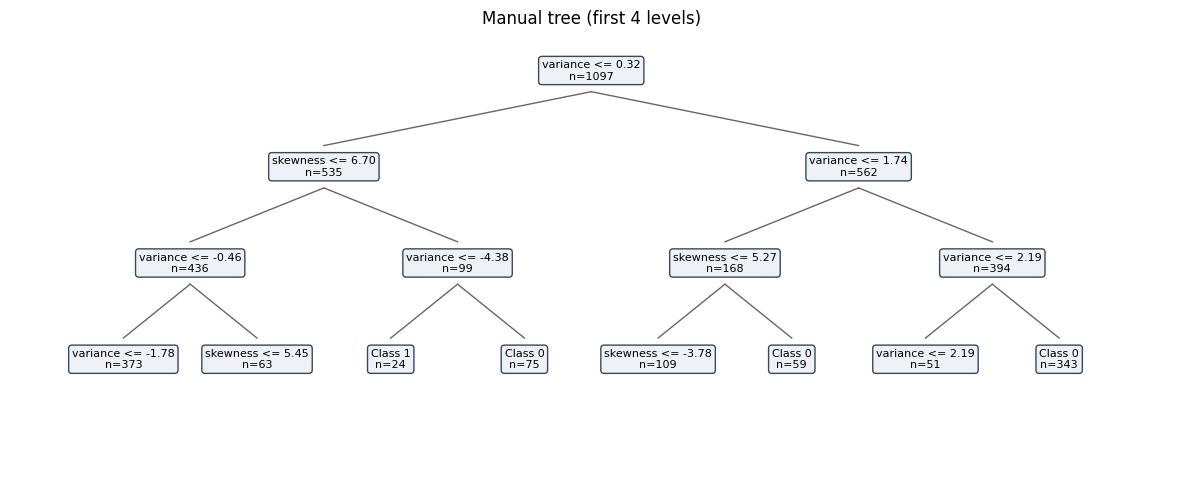

In [7]:
def draw_manual_tree(tree, names, max_level=3):
    fig, ax = plt.subplots(figsize=(15, 6))
    ax.set(xlim=(0, 1), ylim=(-.1, 1.1))
    ax.axis('off')
    def traverse(node, px, py, span, level):
        text = (f"{names[node['feature']]} <= {node['threshold']:.2f}\nn={node['n']}"
                if 'feature' in node else f"Class {node['label']}\nn={node['n']}")
        ax.text(px, py, text, ha='center', va='center', fontsize=8,
                bbox=dict(boxstyle='round', fc='#eef2f6', ec='#34495e'))
        if 'feature' not in node or level >= max_level:
            return
        for sign, side in [(-1, 'left'), (1, 'right')]:
            xx, yy = px + sign * span, py - .25
            ax.plot([px, xx], [py-.055, yy+.055], color='#666', lw=1)
            traverse(node[side], xx, yy, span / 2, level+1)
    traverse(tree.root_, .5, 1, .23, 0)
    plt.title(f'Manual tree (first {max_level + 1} levels)')
    plt.show()

draw_manual_tree(own_tree_2, ('variance', 'skewness'))

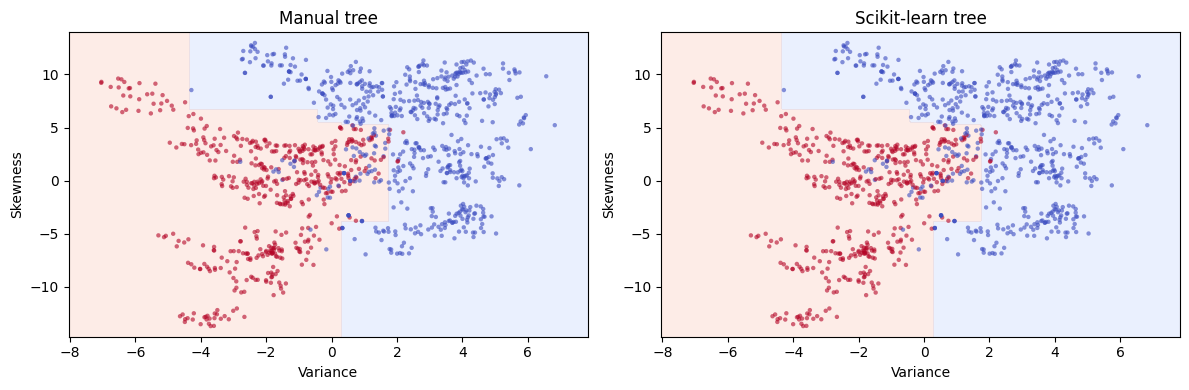

In [8]:
def draw_regions(axis, classifier, points, labels, heading, scales=None):
    x0, x1 = points[:, 0], points[:, 1]
    xx, yy = np.meshgrid(np.linspace(x0.min()-1, x0.max()+1, 240),
                         np.linspace(x1.min()-1, x1.max()+1, 240))
    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_input = scales.transform(grid) if scales is not None else grid
    result = classifier.predict(grid_input).reshape(xx.shape)
    axis.contourf(xx, yy, result, alpha=.18, levels=[-.5, .5, 1.5], cmap='coolwarm')
    axis.scatter(x0, x1, c=labels, s=10, cmap='coolwarm', alpha=.6, edgecolors='none')
    axis.set(title=heading, xlabel='Variance', ylabel='Skewness')

fig, sides = plt.subplots(1, 2, figsize=(12, 4))
draw_regions(sides[0], own_tree_2, train_2, y_train, 'Manual tree')
draw_regions(sides[1], sk_tree_2, train_2, y_train, 'Scikit-learn tree')
plt.tight_layout(); plt.show()

,criterion,depth,manual_train,manual_test,sklearn_test,agreement
0,gini,1,0.860529,0.825455,0.825455,1.000000
1,gini,2,0.907019,0.861818,0.861818,1.000000
2,gini,3,0.928897,0.880000,0.880000,1.000000
3,gini,4,0.938924,0.901818,0.901818,1.000000
4,gini,6,0.958067,0.880000,0.880000,1.000000
5,gini,10,0.992707,0.894545,0.894545,1.000000
6,entropy,1,0.851413,0.796364,0.796364,1.000000
7,entropy,2,0.907931,0.850909,0.850909,1.000000
8,entropy,3,0.937101,0.876364,0.876364,1.000000
9,entropy,4,0.937101,0.876364,0.876364,1.000000


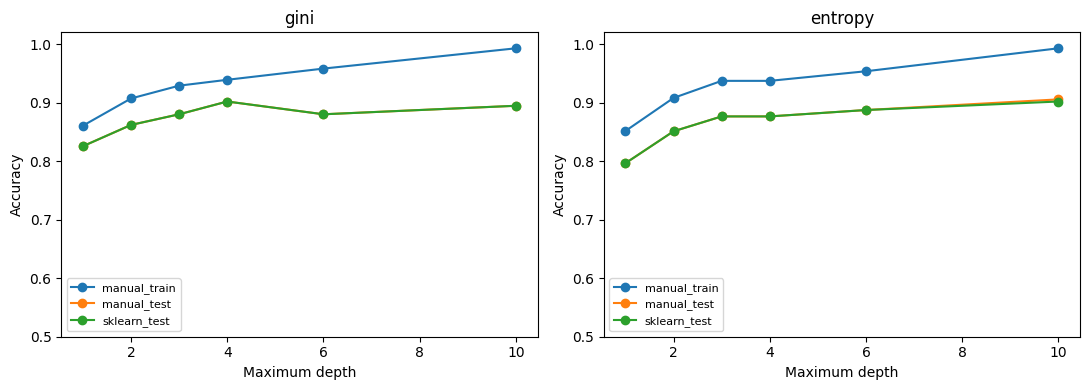

In [9]:
tree_rows = []
for metric in ('gini', 'entropy'):
    for depth in (1, 2, 3, 4, 6, 10):
        scratch = ScratchTree(depth_limit=depth, criterion=metric).fit(train_2, y_train)
        library = DecisionTreeClassifier(criterion=metric, max_depth=depth, random_state=SEED).fit(train_2, y_train)
        tree_rows.append({'criterion': metric, 'depth': depth,
                          'manual_train': accuracy_score(y_train, scratch.predict(train_2)),
                          'manual_test': accuracy_score(y_test, scratch.predict(test_2)),
                          'sklearn_test': accuracy_score(y_test, library.predict(test_2)),
                          'agreement': np.mean(scratch.predict(test_2) == library.predict(test_2))})
tree_trials = pd.DataFrame(tree_rows)
display(tree_trials)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axs, ('gini', 'entropy')):
    part = tree_trials[tree_trials.criterion == metric]
    for col in ('manual_train', 'manual_test', 'sklearn_test'):
        ax.plot(part.depth, part[col], marker='o', label=col)
    ax.set(title=metric, xlabel='Maximum depth', ylabel='Accuracy', ylim=(.5, 1.02))
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## PART B.

Manual / sklearn test accuracy: 0.8290909090909091 0.8290909090909091


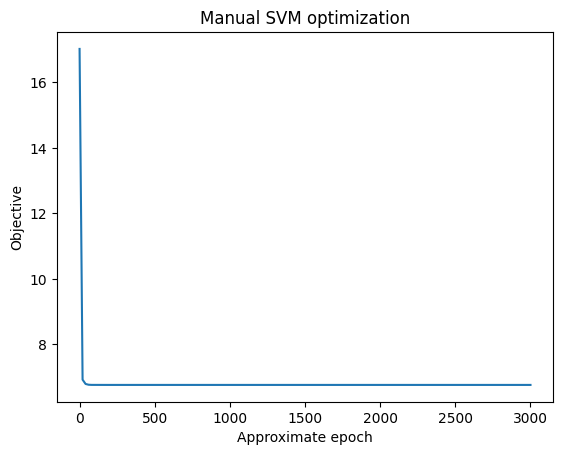

In [10]:
two_scaler = StandardScaler().fit(train_2)
tr_scaled = two_scaler.transform(train_2)
te_scaled = two_scaler.transform(test_2)
y_signed = 2*y_train - 1

class ScratchLinearSVM:
    def __init__(self, C=20, step=0.01, epochs=3000):
        self.C, self.step, self.epochs = C, step, epochs

    def fit(self, X, y):
        self.weights_ = np.zeros(X.shape[1])
        self.bias_ = 0.
        self.losses_ = []
        for iteration in range(self.epochs):
            margin = y * (X @ self.weights_ + self.bias_)
            active = margin < 1
            dw = self.weights_ - self.C * (X[active].T @ y[active]) / len(y)
            db = -self.C * y[active].sum() / len(y)
            # Mildly decaying step reduces oscillation around the hinge kink.
            rate = self.step / np.sqrt(1 + iteration / 250)
            self.weights_ -= rate * dw
            self.bias_ -= rate * db
            if iteration % 20 == 0 or iteration == self.epochs - 1:
                hinge = np.maximum(0, 1 - y * (X @ self.weights_ + self.bias_))
                self.losses_.append(.5*np.dot(self.weights_, self.weights_) + self.C*hinge.mean())
        return self

    def decision_function(self, X):
        return X @ self.weights_ + self.bias_

    def predict(self, X):
        return (self.decision_function(X) >= 0).astype(int)

hand_svm_2 = ScratchLinearSVM().fit(tr_scaled, y_signed)
sk_svm_2 = SVC(kernel='linear', C=hand_svm_2.C / len(y_train)).fit(tr_scaled, y_train)
print('Manual / sklearn test accuracy:',
      accuracy_score(y_test, hand_svm_2.predict(te_scaled)),
      accuracy_score(y_test, sk_svm_2.predict(te_scaled)))
plt.plot(np.arange(len(hand_svm_2.losses_))*20, hand_svm_2.losses_)
plt.xlabel('Approximate epoch'); plt.ylabel('Objective'); plt.title('Manual SVM optimization'); plt.show()

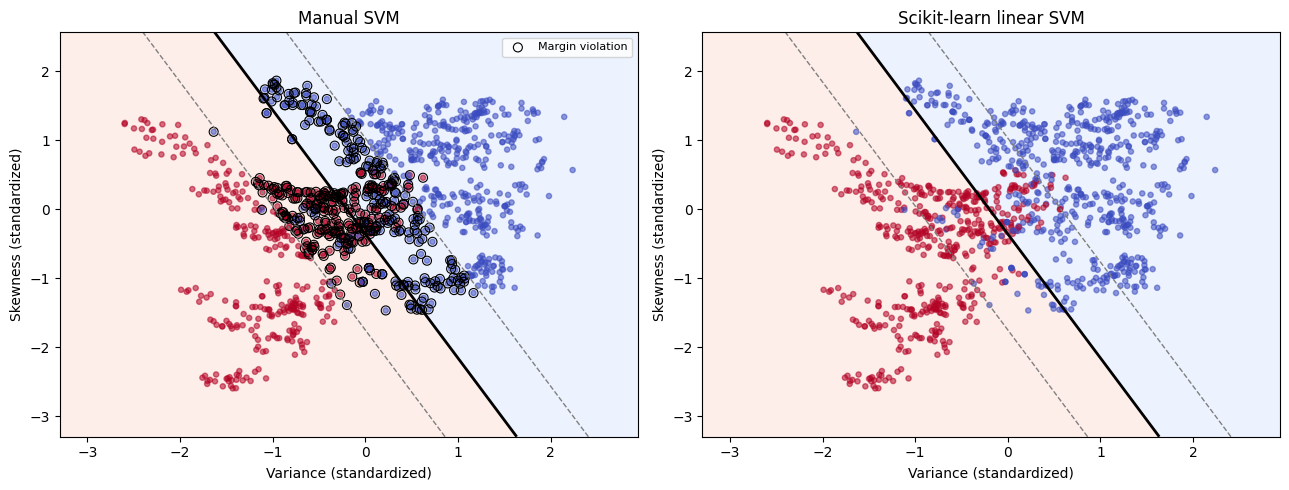

Margin violations on training set: 432


In [11]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
mesh_x, mesh_y = np.meshgrid(np.linspace(tr_scaled[:,0].min()-.7, tr_scaled[:,0].max()+.7, 300),
                             np.linspace(tr_scaled[:,1].min()-.7, tr_scaled[:,1].max()+.7, 300))
mesh = np.c_[mesh_x.ravel(), mesh_y.ravel()]
for ax, classifier, title in zip(axs, (hand_svm_2, sk_svm_2), ('Manual SVM', 'Scikit-learn linear SVM')):
    score = classifier.decision_function(mesh).reshape(mesh_x.shape)
    ax.contourf(mesh_x, mesh_y, score > 0, levels=[-.5,.5,1.5], alpha=.16, cmap='coolwarm')
    ax.contour(mesh_x, mesh_y, score, levels=[-1,0,1], colors=['gray','black','gray'],
               linestyles=['--','-','--'], linewidths=[1,2,1])
    ax.scatter(tr_scaled[:,0], tr_scaled[:,1], c=y_train, cmap='coolwarm', s=14, alpha=.55)
    ax.set(title=title, xlabel='Variance (standardized)', ylabel='Skewness (standardized)')
violations = y_signed * hand_svm_2.decision_function(tr_scaled) < 1
axs[0].scatter(tr_scaled[violations,0], tr_scaled[violations,1], s=42,
               facecolors='none', edgecolors='black', linewidths=.8, label='Margin violation')
axs[0].legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()
print('Margin violations on training set:', violations.sum())

,parameter,value,train_accuracy,test_accuracy,final_objective
0,C,1.000,0.857794,0.814545,0.675580
1,C,10.000,0.887876,0.832727,3.835565
2,C,20.000,0.889699,0.829091,6.766175
3,C,80.000,0.894257,0.836364,22.978249
4,step,0.001,0.886964,0.829091,6.766193
5,step,0.010,0.889699,0.829091,6.766175
6,step,0.050,0.889699,0.829091,6.766179
7,epochs,250.000,0.889699,0.829091,6.766175
8,epochs,1000.000,0.889699,0.829091,6.766174
9,epochs,3000.000,0.889699,0.829091,6.766175


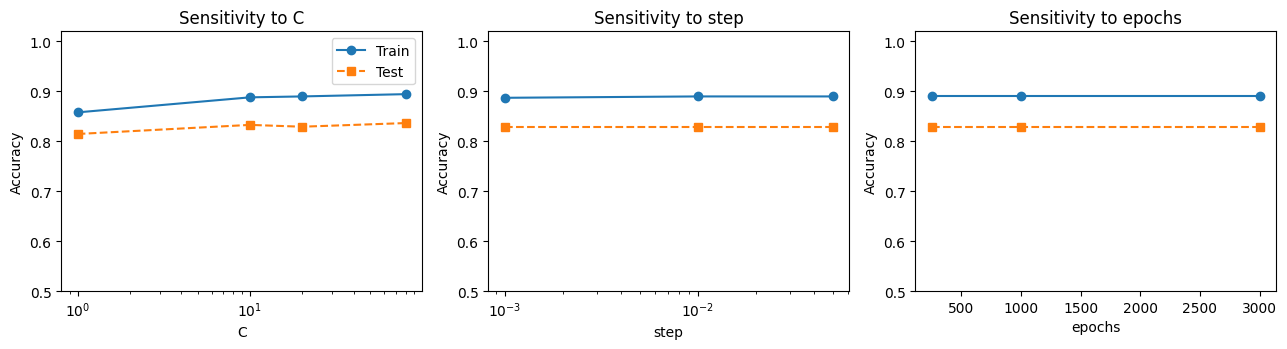

In [12]:
svm_records = []
settings = [('C', [1, 10, 20, 80]), ('step', [.001, .01, .05]), ('epochs', [250, 1000, 3000])]
for changing, values in settings:
    for value in values:
        options = {'C':20, 'step':.01, 'epochs':3000}
        options[changing] = value
        trained = ScratchLinearSVM(**options).fit(tr_scaled, y_signed)
        svm_records.append({'parameter': changing, 'value': value,
                            'train_accuracy': accuracy_score(y_train, trained.predict(tr_scaled)),
                            'test_accuracy': accuracy_score(y_test, trained.predict(te_scaled)),
                            'final_objective': trained.losses_[-1]})
svm_trials = pd.DataFrame(svm_records)
display(svm_trials)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (param, _) in zip(axs, settings):
    subset = svm_trials[svm_trials.parameter == param]
    ax.plot(subset.value, subset.train_accuracy, 'o-', label='Train')
    ax.plot(subset.value, subset.test_accuracy, 's--', label='Test')
    if param in ('C', 'step'): ax.set_xscale('log')
    ax.set(xlabel=param, ylabel='Accuracy', title=f'Sensitivity to {param}', ylim=(.5,1.02))
axs[0].legend(); plt.tight_layout(); plt.show()

## PART C.


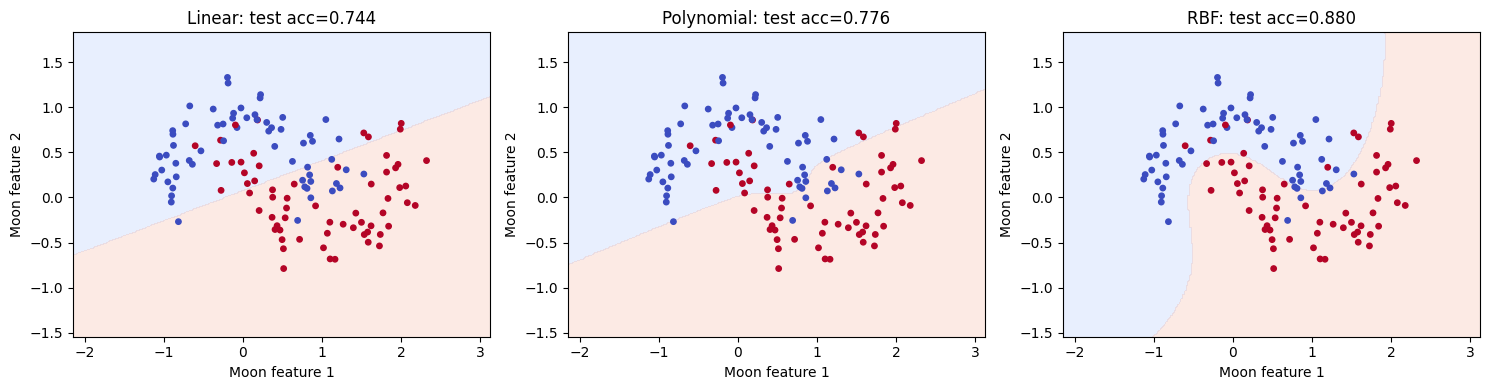

In [13]:
moon_points, moon_labels = make_moons(n_samples=500, noise=.22, random_state=SEED)
m_train, m_test, my_train, my_test = train_test_split(moon_points, moon_labels,
    test_size=.25, stratify=moon_labels, random_state=SEED)
moon_scaler = StandardScaler().fit(m_train)
a_train, a_test = moon_scaler.transform(m_train), moon_scaler.transform(m_test)
kernels = {'Linear': SVC(kernel='linear', C=1),
           'Polynomial': SVC(kernel='poly', degree=3, gamma='scale', C=1),
           'RBF': SVC(kernel='rbf', gamma='scale', C=1)}
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
x_mesh, y_mesh = np.meshgrid(np.linspace(moon_points[:,0].min()-.5, moon_points[:,0].max()+.5, 250),
                              np.linspace(moon_points[:,1].min()-.5, moon_points[:,1].max()+.5, 250))
original_grid = np.c_[x_mesh.ravel(), y_mesh.ravel()]
for ax, (name, classifier) in zip(axs, kernels.items()):
    classifier.fit(a_train, my_train)
    z = classifier.predict(moon_scaler.transform(original_grid)).reshape(x_mesh.shape)
    ax.contourf(x_mesh, y_mesh, z, alpha=.2, levels=[-.5,.5,1.5], cmap='coolwarm')
    ax.scatter(m_test[:,0], m_test[:,1], c=my_test, cmap='coolwarm', s=15)
    ax.set(title=f'{name}: test acc={accuracy_score(my_test, classifier.predict(a_test)):.3f}',
           xlabel='Moon feature 1', ylabel='Moon feature 2')
plt.tight_layout(); plt.show()

## PART D.

,accuracy,precision,recall,f1,train_s,predict_s
model,,,,,,
Manual tree,0.9564,0.9435,0.9590,0.9512,0.0077,0.0003
Sklearn tree,0.9564,0.9435,0.9590,0.9512,0.0044,0.0005
Manual linear SVM,0.9636,0.9375,0.9836,0.9600,0.2503,0.0000
Sklearn linear SVM,0.9636,0.9375,0.9836,0.9600,0.0110,0.0024
RBF SVM,1.0000,1.0000,1.0000,1.0000,0.0066,0.0031


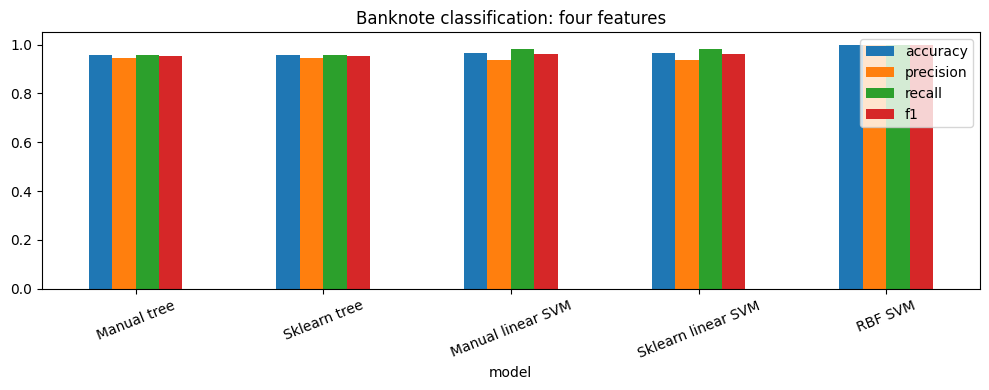

In [14]:
all_scaler = StandardScaler().fit(train_all)
tr4_z, te4_z = all_scaler.transform(train_all), all_scaler.transform(test_all)

comparisons = [
    ('Manual tree', ScratchTree(depth_limit=5), train_all, test_all, False),
    ('Sklearn tree', DecisionTreeClassifier(max_depth=5, random_state=SEED), train_all, test_all, False),
    ('Manual linear SVM', ScratchLinearSVM(C=20, epochs=3000), tr4_z, te4_z, True),
    ('Sklearn linear SVM', SVC(kernel='linear', C=20/len(y_train)), tr4_z, te4_z, False),
    ('RBF SVM', SVC(kernel='rbf', C=1, gamma='scale'), tr4_z, te4_z, False),
]
summary = []
for name, estimator, data_tr, data_te, signed_labels in comparisons:
    tic = perf_counter()
    estimator.fit(data_tr, 2*y_train-1 if signed_labels else y_train)
    training_seconds = perf_counter() - tic
    tic = perf_counter()
    predicted = estimator.predict(data_te)
    predicting_seconds = perf_counter() - tic
    summary.append({'model':name, 'accuracy':accuracy_score(y_test,predicted),
                    'precision':precision_score(y_test,predicted,zero_division=0),
                    'recall':recall_score(y_test,predicted,zero_division=0),
                    'f1':f1_score(y_test,predicted,zero_division=0),
                    'train_s':training_seconds, 'predict_s':predicting_seconds})
scoreboard = pd.DataFrame(summary).set_index('model')
display(scoreboard.round(4))
scoreboard[['accuracy','precision','recall','f1']].plot(kind='bar', figsize=(10,4), ylim=(0,1.05), rot=22,
                                                     title='Banknote classification: four features')
plt.tight_layout(); plt.show()